In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Timing experiments
import time

# Feature scaling and preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

# Pipeline construction
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline

# Class imbalance
from imblearn.over_sampling import SMOTE, RandomOverSampler

In [2]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

# Random Forest
from sklearn.ensemble import RandomForestClassifier

# Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

# XGBoost
from xgboost import XGBClassifier

# LightGBM
from lightgbm import LGBMClassifier

# CatBoost
from catboost import CatBoostClassifier

# Cross-validation
from sklearn.model_selection import StratifiedKFold, cross_validate

# Classification metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc
)

# Hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

# Model explainability
import shap

/home/emmizzy119/fraud-detection-system/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from pathlib import Path

# Directory containing the prepared data partitions
Split_Dir = Path("../data/processed")

# File paths
X_train_path = Split_Dir / "X_train.csv"
X_test_path = Split_Dir / "X_test.csv"
y_train_path = Split_Dir / "y_train.csv"
y_test_path = Split_Dir / "y_test.csv"

# Check whether all files exist
files ={
    "X_train": X_train_path,
    "X_test": X_test_path,
    "y_train": y_train_path,
    "y_test": y_test_path
}

for name, path in files.items():
    print(f"{name}: {'found' if path.exists() else 'not found'} - {path}")

X_train: found - ../data/processed/X_train.csv
X_test: found - ../data/processed/X_test.csv
y_train: found - ../data/processed/y_train.csv
y_test: found - ../data/processed/y_test.csv


In [4]:
X_train = pd.read_csv(X_train_path)
X_test = pd.read_csv(X_test_path)

y_train = pd.read_csv(y_train_path).squeeze("columns")
y_test = pd.read_csv(y_test_path).squeeze("columns")

print("Data loaded successfully.")

Data loaded successfully.


In [5]:
print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("\nTest features:", X_test.shape)
print("Test target:", y_test.shape)

Training features: (226980, 30)
Training target: (226980,)

Test features: (56746, 30)
Test target: (56746,)


In [6]:
print("Training target classes:")
print(y_train.value_counts().sort_index())

print("\nTest target classes:")
print(y_test.value_counts().sort_index())

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTest target proportions:")
print(y_test.value_counts(normalize=True).sort_index())

Training target classes:
Class
0    226602
1       378
Name: count, dtype: int64

Test target classes:
Class
0    56651
1       95
Name: count, dtype: int64

Training target proportions:
Class
0    0.998335
1    0.001665
Name: proportion, dtype: float64

Test target proportions:
Class
0    0.998326
1    0.001674
Name: proportion, dtype: float64


In [7]:
print("Same feature columns:", X_train.columns.equals(X_test.columns))
print("Training feature count:", X_train.shape[1])
print("Test feature count:", X_test.shape[1])

print("\nTraining columns:")
print(X_train.columns.tolist())

Same feature columns: True
Training feature count: 30
Test feature count: 30

Training columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [8]:
# Reproducibile experiment configuration
RANDOM_STATE = 42
N_SPLITS = 5

# Five-fold stratifired cross-validation
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

print(f"Number of folds: {N_SPLITS}")
print(f"Random state: {RANDOM_STATE}")

Number of folds: 5
Random state: 42


In [9]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "average_precision": "average_precision",
    "roc_auc": "roc_auc"
}

print("Evaluation metrics:")
for metric in scoring:
    print(f"- {metric}")

Evaluation metrics:
- accuracy
- precision
- recall
- f1
- average_precision
- roc_auc


In [10]:
# Models to compare
MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Gradient Boosting",
    "XGBoost",
    "LightGBM",
    "CatBoost"
]

# Imbalance-handling strategies
STRATEGY_NAMES = [
    "Class Weighting",
    "SMOTE Oversampling",
    "Random Undersampling"
]

TOTAL_EXPERIMENTS = len(MODEL_NAMES) * len(STRATEGY_NAMES)

print(f"Number of models: {len(MODEL_NAMES)}")
print(f"Number of imbalance strategies: {len(STRATEGY_NAMES)}")
print(f"Total model-strategy combinations: {TOTAL_EXPERIMENTS}")
print(f"Total cross-validation fits: {TOTAL_EXPERIMENTS * N_SPLITS}")

Number of models: 6
Number of imbalance strategies: 3
Total model-strategy combinations: 18
Total cross-validation fits: 90


In [11]:
# 1. Logistic Regression
logistic_regression = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

# 2. Random Forest
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=2
)

# 3. Gradient Boosting
gradient_boosting = GradientBoostingClassifier(
    random_state=RANDOM_STATE
)

# 4. XGBoost
xgboost_model = XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric="logloss",
    n_jobs=-1
)

# 5. LightGBM
lightgbm_model = LGBMClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

# 6. CatBoost
catboost_model = CatBoostClassifier(
    random_seed=RANDOM_STATE,
    verbose=0,
    thread_count=-1
)

# Collect the models
models = {
    "Logistic Regression": logistic_regression,
    "Random Forest": random_forest,
    "Gradient Boosting": gradient_boosting,
    "XGBoost": xgboost_model,
    "LightGBM": lightgbm_model,
    "CatBoost": catboost_model
}

print(f"Models defined: {len(models)}")

for name in models:
    print(name)

Models defined: 6
Logistic Regression
Random Forest
Gradient Boosting
XGBoost
LightGBM
CatBoost


In [12]:
from imblearn.under_sampling import RandomUnderSampler

In [13]:
# Columns to scale for Logistic Regression
scale_columns = ["Time", "Amount"]

# All predictors are numerical
all_feature_columns = X_train.columns.tolist()

print("Number of features:", len(all_feature_columns))
print("Columns scaled for Logistic Regression:", scale_columns)
print("Features scaled before SMOTE:", len(all_feature_columns))

Number of features: 30
Columns scaled for Logistic Regression: ['Time', 'Amount']
Features scaled before SMOTE: 30


In [14]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler


def build_pipeline(model, strategy):
    """Build a model pipeline for the selected imbalance strategy."""

    model = clone(model)
    steps = []

    supported_models = (
        LogisticRegression,
        RandomForestClassifier,
        GradientBoostingClassifier,
        XGBClassifier,
        LGBMClassifier,
        CatBoostClassifier
    )

    if not isinstance(model, supported_models):
        raise TypeError(f"Unsupported model type: {type(model).__name__}")

    if strategy == "Class Weighting":

        if isinstance(model, LogisticRegression):
            steps.append((
                "scaler",
                ColumnTransformer(
                    transformers=[
                        ("scale", StandardScaler(), ["Time", "Amount"])
                    ],
                    remainder="passthrough"
                )
            ))

        if isinstance(model, (LogisticRegression, RandomForestClassifier)):
            model.set_params(class_weight="balanced")

        elif isinstance(model, XGBClassifier):
            model = ClassWeightedClassifier(model)

        elif isinstance(model, GradientBoostingClassifier):
            model = ClassWeightedClassifier(model)

        elif isinstance(model, LGBMClassifier):
            model.set_params(class_weight="balanced")

        elif isinstance(model, CatBoostClassifier):
            model.set_params(auto_class_weights="Balanced")

    elif strategy == "SMOTE Oversampling":
        steps.append(("scaler", StandardScaler()))
        steps.append(("sampler", SMOTE(random_state=RANDOM_STATE)))

    elif strategy == "Random Undersampling":

        if isinstance(model, LogisticRegression):
            steps.append((
                "scaler",
                ColumnTransformer(
                    transformers=[
                        ("scale", StandardScaler(), ["Time", "Amount"])
                    ],
                    remainder="passthrough"
                )
            ))

        steps.append((
            "sampler",
            RandomUnderSampler(random_state=RANDOM_STATE)
        ))

    else:
        raise ValueError(f"Unknown strategy: {strategy}")

    steps.append(("classifier", model))

    return ImbPipeline(steps=steps)

In [15]:
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.utils.validation import check_is_fitted


class ClassWeightedClassifier(ClassifierMixin, BaseEstimator):

    def __init__(self, estimator):
        self.estimator = estimator

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)

        # Calculate weights using this fold's training labels.
        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y
        )

        # XGBoost uses scale_pos_weight instead.
        if isinstance(self.estimator_, XGBClassifier):
            class_counts = np.bincount(np.asarray(y, dtype=int))
            self.estimator_.set_params(
                scale_pos_weight=class_counts[0] / class_counts[1]
            )
            self.estimator_.fit(X, y)

        # Gradient Boosting accepts sample_weight directly.
        elif isinstance(self.estimator_, GradientBoostingClassifier):
            self.estimator_.fit(
                X, y,
                sample_weight=sample_weights
            )

        else:
            raise TypeError(
                "This wrapper supports Gradient Boosting and XGBoost."
            )

        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        check_is_fitted(self, "estimator_")
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        check_is_fitted(self, "estimator_")
        return self.estimator_.predict_proba(X) 

In [16]:
def evaluate_model(model, strategy, X_train, y_train, cv, scoring):
    """
    Evaluate one model-strategy combination using cross-validation.
    """

    pipeline = build_pipeline(model, strategy)

    start_time = time.time()

    cv_results = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=2,
        return_train_score=False,
        error_score="raise"
    )

    elapsed_time = time.time() - start_time

    results = {
        "model": type(model).__name__,
        "strategy": strategy,
        "total_time_seconds": elapsed_time
    }

    for metric in scoring:
        scores = cv_results[f"test_{metric}"]

        results[f"{metric}_mean"] = scores.mean()
        results[f"{metric}_std"] = scores.std()

    return results

In [17]:
experiments = {
    f"{model_name} - {strategy}": {
        "model": model,
        "strategy": strategy
    }
    for model_name, model in models.items()
    for strategy in STRATEGY_NAMES
}

In [18]:
print(f"Total experiments: {len(experiments)}")

for experiment_name in experiments:
    print(experiment_name)

Total experiments: 18
Logistic Regression - Class Weighting
Logistic Regression - SMOTE Oversampling
Logistic Regression - Random Undersampling
Random Forest - Class Weighting
Random Forest - SMOTE Oversampling
Random Forest - Random Undersampling
Gradient Boosting - Class Weighting
Gradient Boosting - SMOTE Oversampling
Gradient Boosting - Random Undersampling
XGBoost - Class Weighting
XGBoost - SMOTE Oversampling
XGBoost - Random Undersampling
LightGBM - Class Weighting
LightGBM - SMOTE Oversampling
LightGBM - Random Undersampling
CatBoost - Class Weighting
CatBoost - SMOTE Oversampling
CatBoost - Random Undersampling


In [19]:
experiment_results = []

for experiment_name, experiment_config in experiments.items():

    print(f"\nRunning: {experiment_name}")

    results = evaluate_model(
        model=experiment_config["model"],
        strategy=experiment_config["strategy"],
        X_train=X_train,
        y_train=y_train,
        cv=cv,
        scoring=scoring
    )

    experiment_results.append(results)

    print(
        f"Average Precision: "
        f"{results['average_precision_mean']:.4f}"
    )

    print(
        f"Recall: "
        f"{results['recall_mean']:.4f}"
    )

    print(
        f"Elapsed time: "
        f"{results['total_time_seconds']:.2f} seconds"
    )


Running: Logistic Regression - Class Weighting
Average Precision: 0.7541
Recall: 0.9179
Elapsed time: 14.58 seconds

Running: Logistic Regression - SMOTE Oversampling
Average Precision: 0.7518
Recall: 0.9073
Elapsed time: 16.28 seconds

Running: Logistic Regression - Random Undersampling
Average Precision: 0.6023
Recall: 0.9126
Elapsed time: 1.74 seconds

Running: Random Forest - Class Weighting
Average Precision: 0.8347
Recall: 0.7882
Elapsed time: 151.42 seconds

Running: Random Forest - SMOTE Oversampling
Average Precision: 0.8425
Recall: 0.8227
Elapsed time: 742.75 seconds

Running: Random Forest - Random Undersampling
Average Precision: 0.7579
Recall: 0.8941
Elapsed time: 2.98 seconds

Running: Gradient Boosting - Class Weighting
Average Precision: 0.7321
Recall: 0.8862
Elapsed time: 1109.86 seconds

Running: Gradient Boosting - SMOTE Oversampling
Average Precision: 0.7652
Recall: 0.8836
Elapsed time: 2677.67 seconds

Running: Gradient Boosting - Random Undersampling
Average Prec

/home/emmizzy119/fraud-detection-system/.venv/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Average Precision: 0.8380
Recall: 0.8413
Elapsed time: 178.70 seconds

Running: CatBoost - SMOTE Oversampling
Average Precision: 0.8373
Recall: 0.8413
Elapsed time: 368.83 seconds

Running: CatBoost - Random Undersampling
Average Precision: 0.7342
Recall: 0.9047
Elapsed time: 32.57 seconds


In [20]:
import pandas as pd
from pathlib import Path

# Convert the list of result dictionaries into a DataFrame
results_df = pd.DataFrame(experiment_results)

# Sort experiments by Average Precision, highest first
results_df = results_df.sort_values(
    by="average_precision_mean",
    ascending=False
).reset_index(drop=True)

# Display the results
results_df

,model,strategy,total_time_seconds,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std
0,XGBClassifier,Class Weighting,15.788576,0.999590,0.000062,0.926904,0.025173,0.820035,0.046357,0.869012,0.022791,0.848342,0.029766,0.978911,0.005033
1,XGBClassifier,SMOTE Oversampling,31.825407,0.999299,0.000101,0.775456,0.048408,0.822702,0.050679,0.796400,0.028219,0.843567,0.033383,0.977584,0.005534
2,RandomForestClassifier,SMOTE Oversampling,742.748949,0.999537,0.000084,0.892634,0.034240,0.822737,0.043013,0.855322,0.027404,0.842494,0.028746,0.973781,0.014893
3,CatBoostClassifier,Class Weighting,178.696434,0.999423,0.000092,0.819795,0.037613,0.841263,0.044847,0.829183,0.026861,0.838022,0.039847,0.975693,0.005212
4,CatBoostClassifier,SMOTE Oversampling,368.832210,0.999013,0.000124,0.663605,0.043614,0.841263,0.040016,0.740168,0.023637,0.837327,0.036461,0.973078,0.004705
5,RandomForestClassifier,Class Weighting,151.416891,0.999533,0.000069,0.921052,0.020973,0.788246,0.051903,0.848139,0.026879,0.834693,0.027444,0.959212,0.015570
6,LGBMClassifier,Class Weighting,365.338031,0.999493,0.000101,0.867024,0.031061,0.822667,0.050693,0.843440,0.033225,0.828779,0.021267,0.966521,0.010305
7,LGBMClassifier,SMOTE Oversampling,396.603444,0.998885,0.000166,0.626994,0.051759,0.838596,0.032844,0.715963,0.032560,0.792850,0.037155,0.972371,0.004095
8,GradientBoostingClassifier,SMOTE Oversampling,2677.671663,0.990453,0.001345,0.137910,0.016212,0.883579,0.031641,0.238139,0.024396,0.765207,0.030582,0.977930,0.010439
9,RandomForestClassifier,Random Undersampling,2.977862,0.979571,0.002752,0.069568,0.008845,0.894140,0.032367,0.128953,0.015229,0.757918,0.053193,0.979060,0.010624


In [21]:
results_df[
    [
        "model",
        "strategy",
        "accuracy_mean",
        "precision_mean",
        "recall_mean",
        "f1_mean",
        "average_precision_mean",
        "roc_auc_mean",
        "total_time_seconds"
    ]
]

,model,strategy,accuracy_mean,precision_mean,recall_mean,f1_mean,average_precision_mean,roc_auc_mean,total_time_seconds
0,XGBClassifier,Class Weighting,0.999590,0.926904,0.820035,0.869012,0.848342,0.978911,15.788576
1,XGBClassifier,SMOTE Oversampling,0.999299,0.775456,0.822702,0.796400,0.843567,0.977584,31.825407
2,RandomForestClassifier,SMOTE Oversampling,0.999537,0.892634,0.822737,0.855322,0.842494,0.973781,742.748949
3,CatBoostClassifier,Class Weighting,0.999423,0.819795,0.841263,0.829183,0.838022,0.975693,178.696434
4,CatBoostClassifier,SMOTE Oversampling,0.999013,0.663605,0.841263,0.740168,0.837327,0.973078,368.832210
5,RandomForestClassifier,Class Weighting,0.999533,0.921052,0.788246,0.848139,0.834693,0.959212,151.416891
6,LGBMClassifier,Class Weighting,0.999493,0.867024,0.822667,0.843440,0.828779,0.966521,365.338031
7,LGBMClassifier,SMOTE Oversampling,0.998885,0.626994,0.838596,0.715963,0.792850,0.972371,396.603444
8,GradientBoostingClassifier,SMOTE Oversampling,0.990453,0.137910,0.883579,0.238139,0.765207,0.977930,2677.671663
9,RandomForestClassifier,Random Undersampling,0.979571,0.069568,0.894140,0.128953,0.757918,0.979060,2.977862


In [22]:
from pathlib import Path

results_dir = Path("../data/processed")
results_dir.mkdir(parents=True, exist_ok=True)

results_path = results_dir / "experiment_results.csv"

results_df.to_csv(results_path, index=False)

print(f"Results saved to: {results_path.resolve()}")

Results saved to: /home/emmizzy119/fraud-detection-system/data/processed/experiment_results.csv


In [23]:
xgb_class_weight_pipeline = build_pipeline(
    model=models["XGBoost"],
    strategy="Class Weighting"
)

In [24]:
xgb_cv_results = cross_validate(
    estimator=xgb_class_weight_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False,
    return_estimator=True,
    error_score="raise"
)

In [25]:
xgb_cv_summary = {
    "model": "XGBoost",
    "strategy": "Class Weighting"
}

for metric in scoring:
    scores = xgb_cv_results[f"test_{metric}"]

    xgb_cv_summary[f"{metric}_mean"] = scores.mean()
    xgb_cv_summary[f"{metric}_std"] = scores.std()

pd.DataFrame([xgb_cv_summary])

,model,strategy,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std
0,XGBoost,Class Weighting,0.99959,0.000062,0.926904,0.025173,0.820035,0.046357,0.869012,0.022791,0.848342,0.029766,0.978911,0.005033


In [27]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold

# Generate the same fold assignments used by cross-validation
folds = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Store each observation's prediction from its held-out fold
oof_predictions = np.zeros(len(y_train), dtype=int)
oof_probabilities = np.zeros(len(y_train), dtype=float)

for fold_idx, (train_idx, val_idx) in enumerate(
    folds.split(X_train, y_train)
):
    # Retrieve the fitted estimator for this fold
    fitted_pipeline = xgb_cv_results["estimator"][fold_idx]

    # Predict only the observations held out from this fold
    X_fold_val = X_train.iloc[val_idx]

    oof_predictions[val_idx] = fitted_pipeline.predict(X_fold_val)

    oof_probabilities[val_idx] = (
        fitted_pipeline.predict_proba(X_fold_val)[:, 1]
    )

print("Out-of-fold predictions generated.")
print("Number of predictions:", len(oof_predictions))

Out-of-fold predictions generated.
Number of predictions: 226980


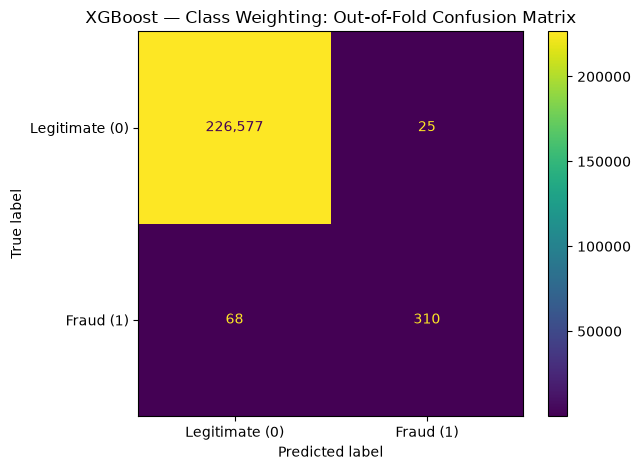

Confusion matrix:
[[226577     25]
 [    68    310]]


In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_train,
    oof_predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate (0)", "Fraud (1)"]
)

display.plot(values_format=",d")
plt.title("XGBoost — Class Weighting: Out-of-Fold Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)

In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

xgb_metrics = {
    "Accuracy": accuracy_score(y_train, oof_predictions),
    "Precision": precision_score(y_train, oof_predictions),
    "Recall": recall_score(y_train, oof_predictions),
    "F1 Score": f1_score(y_train, oof_predictions),
    "Average Precision": average_precision_score(
        y_train, oof_probabilities
    ),
    "ROC-AUC": roc_auc_score(y_train, oof_probabilities)
}

pd.DataFrame(
    xgb_metrics.items(),
    columns=["Metric", "Value"]
)

,Metric,Value
0,Accuracy,0.999590
1,Precision,0.925373
2,Recall,0.820106
3,F1 Score,0.869565
4,Average Precision,0.847170
5,ROC-AUC,0.978893


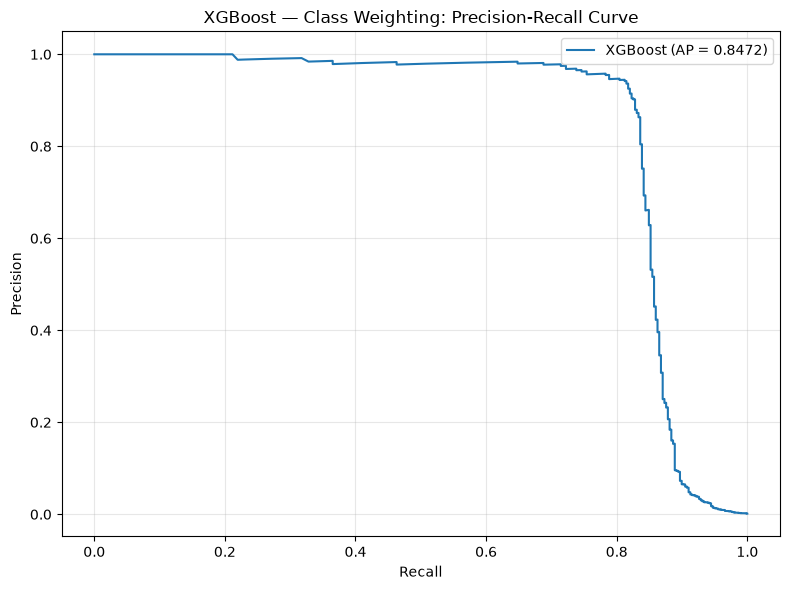

In [30]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Calculate precision and recall across classification thresholds
precision_values, recall_values, thresholds = precision_recall_curve(
    y_train,
    oof_probabilities
)

average_precision = average_precision_score(
    y_train,
    oof_probabilities
)

# Plot the precision-recall curve
plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"XGBoost (AP = {average_precision:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("XGBoost — Class Weighting: Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds_to_test = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

threshold_results = []

for threshold in thresholds_to_test:
    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "fraud_alerts": int(predictions.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,threshold,precision,recall,f1,fraud_alerts
0,0.1,0.8251,0.8360,0.8305,383
1,0.2,0.8678,0.8333,0.8502,363
2,0.3,0.8994,0.8280,0.8623,348
3,0.4,0.9067,0.8228,0.8627,343
4,0.5,0.9254,0.8201,0.8696,335
5,0.6,0.9307,0.8175,0.8704,332
6,0.7,0.9364,0.8175,0.8729,330
7,0.8,0.9364,0.8175,0.8729,330
8,0.9,0.9444,0.8095,0.8718,324


# XGBoost with Class Weighting: Model Investigation and Evaluation

## 1. Objective

This investigation evaluates XGBoost with class weighting as a candidate model for the credit card fraud detection system.

The dataset is highly imbalanced, with legitimate transactions substantially outnumbering fraudulent transactions. Consequently, accuracy alone is insufficient for evaluating model performance. A model could achieve very high accuracy by predicting most transactions as legitimate while failing to detect a meaningful proportion of fraud.

The investigation therefore focuses on precision, recall, F1 score, Average Precision, ROC-AUC, the confusion matrix, and the effect of changing the classification threshold.

The objective is to understand the model's ability to detect fraudulent transactions while controlling false alarms.

## 2. Experimental Configuration

| Component | Configuration |
|---|---|
| Model | XGBoost Classifier |
| Imbalance-handling strategy | Class Weighting |
| Validation method | 5-fold Stratified Cross-Validation |
| Cross-validation predictions | Out-of-fold predictions |
| Positive class | Fraud (`Class = 1`) |
| Negative class | Legitimate (`Class = 0`) |
| Default classification threshold | 0.5 |
| Final test set | Reserved for final model evaluation |

Class weighting assigns greater importance to fraudulent transactions during model training. This helps the classifier learn from the minority class without requiring the original training data to be resampled.

### Evaluation methodology

The initial cross-validation experiment produced a set of metrics for each fold. The fitted estimators were retained using `return_estimator=True`.

Each fitted estimator then predicted the observations belonging to its held-out fold. Combining these predictions produced out-of-fold predictions for the entire training dataset.

This approach provides predictions for observations that were not used to fit the corresponding model, making the combined predictions suitable for investigating classification performance.

The final test set was not used during this investigation.

## 3. Cross-Validation Results

The original five-fold cross-validation experiment produced the following mean metrics and standard deviations.

| Metric | Mean | Standard Deviation |
|---|---:|---:|
| Accuracy | 0.999590 | 0.000062 |
| Precision | 0.926904 | 0.025173 |
| Recall | 0.820035 | 0.046357 |
| F1 score | 0.869012 | 0.022791 |
| Average Precision | 0.848342 | 0.029766 |
| ROC-AUC | 0.978911 | 0.005033 |

### Interpretation

**Accuracy:** The mean accuracy was approximately 99.96%. However, accuracy is not sufficient for judging this model because legitimate transactions dominate the dataset.

**Precision:** Mean precision was approximately 92.69%. This indicates that, on average across the folds, a high proportion of transactions predicted as fraudulent were actually fraudulent.

**Recall:** Mean recall was approximately 82.00%. The model detected approximately 82% of fraudulent transactions across the validation folds, while missing the remainder.

**F1 score:** The mean F1 score was approximately 86.90%, indicating a reasonably strong balance between precision and recall.

**Average Precision:** The mean Average Precision was approximately 84.83%. This summarizes the precision-recall trade-off across classification thresholds and is particularly useful for evaluating models on highly imbalanced datasets.

**ROC-AUC:** The mean ROC-AUC was approximately 97.89%, indicating strong discrimination between fraudulent and legitimate transactions across classification thresholds.

### Cross-validation stability

The standard deviations provide information about variation across folds. ROC-AUC had a relatively small standard deviation of approximately 0.0050, while recall had a larger standard deviation of approximately 0.0464.

This suggests that the model's ranking performance was more consistent across folds than its ability to detect fraud at the default classification threshold.

These standard deviations measure variation between folds; they are not confidence intervals.

## 4. Out-of-Fold Confusion Matrix

The confusion matrix was calculated using the combined out-of-fold predictions.

| Actual Class | Predicted Legitimate (0) | Predicted Fraud (1) |
|---|---:|---:|
| Legitimate (0) | 226,577 | 25 |
| Fraud (1) | 68 | 310 |

The matrix contains four important quantities:

- **True Negatives (TN): 226,577** — legitimate transactions correctly classified as legitimate.
- **False Positives (FP): 25** — legitimate transactions incorrectly classified as fraudulent.
- **False Negatives (FN): 68** — fraudulent transactions incorrectly classified as legitimate.
- **True Positives (TP): 310** — fraudulent transactions correctly classified as fraudulent.

### Confusion matrix interpretation

The model correctly identified 310 fraudulent transactions out of 378 fraudulent transactions in the out-of-fold predictions.

However, it missed 68 fraudulent transactions. These false negatives are important because missed fraud may result in financial losses.

The model also generated 25 false-positive alerts. Although these legitimate transactions were incorrectly flagged, the number of false positives was relatively small compared with the number of legitimate transactions evaluated.

This suggests that the model achieves a useful balance between detecting fraud and limiting false alarms at the default classification threshold.

### Metrics calculated from the out-of-fold predictions

| Metric | Value |
|---|---:|
| Accuracy | 99.9590% |
| Precision | 92.5373% |
| Recall | 82.0106% |
| F1 score | 86.9565% |
| Average Precision | 84.7170% |
| ROC-AUC | 97.8893% |

The out-of-fold metrics differ slightly from the original cross-validation means because the former are calculated from the combined predictions, while the latter average the scores calculated independently for each fold.

### Operational implications

At the default threshold of 0.5, the model detected approximately 82% of fraud cases and maintained precision above 92%.

Nevertheless, the 68 missed fraudulent transactions indicate that there may be opportunities to improve recall. Whether additional fraud detection justifies more false alarms depends on the operational cost of investigating legitimate transactions and the financial impact of missed fraud.

## 5. Precision-Recall Curve

The precision-recall curve evaluates how precision and recall change as the classification threshold varies.

The curve produced an Average Precision score of approximately **0.8472**.

### Observations

**High precision at lower recall levels**

At lower recall levels, precision remained close to 1.0. This indicates that the model can make highly precise fraud predictions when operating at thresholds that identify a smaller subset of the fraudulent transactions.

However, this comes at the cost of missing more fraudulent transactions.

**A relatively strong trade-off at moderate-to-high recall**

As recall increases, precision gradually decreases. The curve maintains relatively high precision across a substantial range of recall values before declining more sharply.

This indicates that the model can detect additional fraud while maintaining useful precision over part of its operating range.

**A sharp decline at high recall**

When recall approaches the upper end of the curve, precision decreases substantially. This suggests that attempting to capture nearly all fraudulent transactions would result in many more legitimate transactions being flagged.

### Interpretation

The precision-recall curve demonstrates why the classification threshold matters.

The default threshold of 0.5 is not necessarily the best operating threshold for a fraud detection system. A higher threshold may reduce false alarms, while a lower threshold may detect more fraud.

The appropriate threshold must be selected according to the desired trade-off between missed fraud and false-positive alerts.

Average Precision summarizes performance across the curve; it does not indicate the precision or recall at any particular threshold.

## 6. ROC Curve and ROC-AUC

The ROC curve examines the relationship between the true-positive rate and the false-positive rate across classification thresholds.

The original cross-validation experiment produced a mean ROC-AUC of approximately **0.9789**, while the combined out-of-fold predictions produced an ROC-AUC of approximately **0.9789**.

### Interpretation

A high ROC-AUC indicates that the model generally assigns higher fraud scores to fraudulent transactions than to legitimate transactions.

However, ROC-AUC must be interpreted alongside the precision-recall results. In a highly imbalanced dataset, the false-positive rate can appear small even when the number of false-positive predictions is operationally meaningful.

The ROC-AUC result is therefore encouraging, but it does not replace the need to examine precision, recall, and the confusion matrix.

## 7. Classification Threshold Analysis

The default classification threshold is 0.5. To investigate alternative operating points, precision, recall, F1 score, and the number of predicted fraud alerts were calculated at nine thresholds.

| Threshold | Precision | Recall | F1 Score | Fraud Alerts |
|---:|---:|---:|---:|---:|
| 0.1 | 0.8251 | 0.8360 | 0.8305 | 383 |
| 0.2 | 0.8678 | 0.8333 | 0.8502 | 363 |
| 0.3 | 0.8994 | 0.8280 | 0.8623 | 348 |
| 0.4 | 0.9067 | 0.8228 | 0.8627 | 343 |
| 0.5 | 0.9254 | 0.8201 | 0.8696 | 335 |
| 0.6 | 0.9307 | 0.8175 | 0.8704 | 332 |
| 0.7 | 0.9364 | 0.8175 | 0.8729 | 330 |
| 0.8 | 0.9364 | 0.8175 | 0.8729 | 330 |
| 0.9 | 0.9444 | 0.8095 | 0.8718 | 324 |

### Observations

**Lower thresholds increase recall**

At a threshold of 0.1, recall increased to 83.60%, compared with 82.01% at the default threshold of 0.5. However, the model generated 383 fraud alerts instead of 335, and precision decreased to 82.51%.

This illustrates the cost of trying to detect additional fraud: more legitimate transactions may be incorrectly flagged.

**Higher thresholds improve precision**

At a threshold of 0.7, precision increased to 93.64%, while recall remained approximately 81.75%. The number of fraud alerts decreased to 330.

At a threshold of 0.9, precision increased further to 94.44%, but recall decreased to 80.95%.

**The highest observed F1 score occurred at thresholds 0.7 and 0.8**

Both thresholds produced an F1 score of 0.8729 in the tested results. However, maximizing F1 alone does not necessarily produce the best operating threshold for a fraud detection application.

The identical results at thresholds 0.7 and 0.8 indicate that these thresholds produced the same predicted classes for the evaluated observations.

### Threshold decision

The results suggest that 0.7 is a useful candidate for further investigation because it produced higher precision than the default threshold without reducing recall relative to the 0.6 threshold.

However, **0.7 is not yet the final selected threshold**. The final decision must consider the business cost of missed fraud and false-positive alerts, as well as the stability of the results.

The test set must remain untouched during threshold selection.

## 8. Strengths and Limitations

### Strengths

- High precision at the default classification threshold.
- Recall of approximately 82%, indicating that the model detects most fraudulent transactions.
- Strong F1 score, reflecting a useful balance between precision and recall.
- High Average Precision, supporting its suitability for further investigation on an imbalanced dataset.
- High ROC-AUC, indicating strong ranking ability.
- Relatively few false-positive alerts in the out-of-fold confusion matrix.
- The threshold analysis provides a practical way to explore alternative operating points.

### Limitations

- The model still misses 68 fraudulent transactions in the combined out-of-fold predictions.
- Lowering the classification threshold increases false-positive alerts.
- Higher precision at a higher threshold can come at the expense of recall.
- Cross-validation results do not guarantee the same performance on unseen data.
- The optimal threshold cannot be determined from the metrics alone without considering operational costs.
- The investigation has not yet established final test-set performance.

## 9. Overall Conclusion

XGBoost with Class Weighting is a strong candidate for the credit card fraud detection system.

The five-fold cross-validation results show high precision, strong ROC-AUC, and a useful balance between precision and recall. The out-of-fold confusion matrix confirms that the model detected 310 of 378 fraudulent transactions while generating 25 false-positive alerts.

The precision-recall curve indicates that the model maintains high precision over a substantial range of recall values, although precision decreases sharply when recall is pushed toward the upper end of the curve.

The threshold analysis suggests that higher thresholds may improve precision and reduce the number of fraud alerts. A threshold of 0.7 is a candidate for further evaluation, but it should not be treated as the final threshold without additional analysis.

**Decision:** Retain XGBoost with Class Weighting as one of the three candidate models. Compare it with Random Forest using SMOTE Oversampling and CatBoost using Class Weighting before choosing a final model.

The next investigation will evaluate Random Forest with SMOTE Oversampling using the same general methodology. After all three candidates have been investigated, their results will be compared before fine-tuning and final model selection.